# Dataset Type

In [1]:
DATASET_TYPE = "downloaded" # Options are "internal" or "downloaded"

# Load Data

In [ ]:
# Import scikit-learn dataset library
from sklearn import datasets

if DATASET_TYPE == "internal":
  ann_data = datasets.load_breast_cancer()

  X = ann_data.data
  y = ann_data.target

  feature_names = ann_data.feature_names
  labels = ann_data.target_names
  cm_labels = labels

# OR: Download Dataset from file

In [2]:
import numpy as np
import pandas as pd

if DATASET_TYPE == "downloaded":

  ann_data = pd.read_csv('https://docs.google.com/spreadsheets/d/1v0SoHvdro_Jm_3eNMBEO16X6wNDFigi9EGycsECS_Lo/pub?output=csv')

  X = ann_data.iloc[:, 2:].to_numpy()
  y = ann_data.iloc[:, 1].to_numpy()
  feature_names = ann_data.columns
  labels = feature_names[1]
  cm_labels = ["malignant", "benign"]

  # Map labels from ['M', 'B'] to [0, 1] space
  y = np.where(y=='M', 0, 1)

# Explore the Data

In [3]:
# print the names of the features
print("Features: ", feature_names)

# print the label type of targets
print("Labels: ", labels)

Features:  Index(['I1', 'O', 'I2', 'I3', 'I4', 'I5', 'I6', 'I7', 'I8', 'I9', 'I10', 'I11',
       'I12', 'I13', 'I14', 'I15', 'I16', 'I17', 'I18', 'I19', 'I20', 'I21',
       'I22', 'I23', 'I24', 'I25', 'I26', 'I26.1', 'I28', 'I29', 'I30', 'I31'],
      dtype='object')
Labels:  O


# Scale the data

In [4]:
# Image processing and pixel values - min-max scaling
# knn-clustering or regression which use distance metrics - standardization
# SVM or logistic regression or Neural Network which use gradiant descent - standardization
# decision tree and random forest - not distance based, hence no scaling is needed

# Normalize the data - Convert to range [0, 1]
X = (X - np.min(X, axis=0)) / (np.max(X, axis=0) - np.min(X, axis=0))

# Standardize the data - Convert to a normal distribution with mean 0 and standard deviation of 1
# X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)

When we normalize the data we are scaling it to be in the range of [0, 1]. This means we take;

X = original data
Xmin = the minimum value in each column
Xmax = the maximum value in each column

and we format the minimum to be 0, and divide it by the shifted range to create a maximum value of 1. This scales the data to be the percentile in a range of min to max, with those respective values representing 0% to 100% of the maximum value in a column.

# Split the Data into Train and Test Sets

In [5]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

# Here we split the training data set, and set it to 70% of the original data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.7)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((170, 30), (399, 30), (170,), (399,))

# Initialize the Model

In [16]:
from sklearn.neural_network import MLPClassifier

# More details about hyperparameters can be found here - 
# https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html

# Here we initialize MLPClassifier from scikit-learn, which is a Multi-Layer Perceptron
# We specify a tuple representing the architecture of the hidden layers in the neural network
# The first layer has 5 neurons,
# The second layer has 7 neurons,
# The third layer has 6 neurons.
# Activation = Rectified Linear Unit which is defined as f(x) = max(0,x)
# Sovler = Adaotive Moment Estimation
# Iteration = max(500) training iterations

# Model was not converging on training, so I had to increase iterations to 2000
mlp = MLPClassifier(hidden_layer_sizes=(5,7,6), activation='relu', solver='adam', max_iter=1000)

Above is where the Model is Initialized.

# Train the Model

In [64]:
import time

# Calculate time before training occurs
time_before = time.time()

mlp.fit(X_train,y_train)

# Calculate time after training occurs and display total time to train
time_after = time.time()
time_elapsed = time_after - time_before
time_elapsed = format(time_elapsed, ".4e")
print("Execution Time:", time_elapsed)

Execution Time: 1.1964e-01


Above is where the Model is trained.

Execution time: Neural Network = 0.1667s, Logistic Regression = 0.002s

It looks like Logistic Regression is training quite a bit faster. But honestly, I get pretty varying execution times from both. However, it looks like the Logistic Regression models generally trains faster. 

# Predict on Test Data

In [65]:
y_pred = mlp.predict(X_test)

# Evaluate on Test data

In [67]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy: how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Model Precision: what percentage of positive tuples are labeled as such?
print("Precision:",metrics.precision_score(y_test, y_pred))

# Model Recall: what percentage of positive tuples are labelled as such?
print("Recall:",metrics.recall_score(y_test, y_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0


# Plot Confusion Matrix

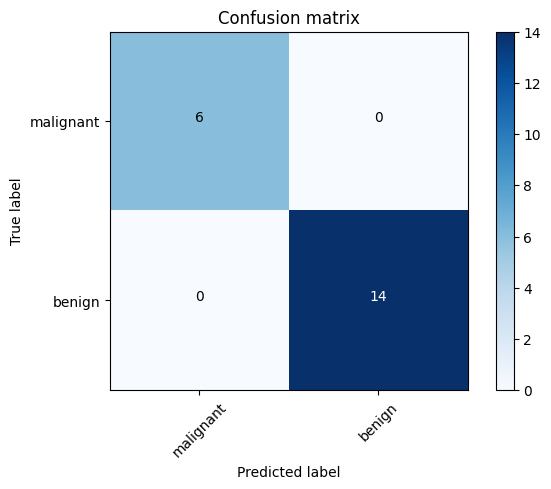

In [68]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion matrix', cmap=plt.cm.Blues):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt), horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

cm = confusion_matrix(y_test, y_pred)

plot_confusion_matrix(cm, cm_labels)  
plt.show()

# Printing Performance Statistics for Part 4

In [76]:
# Assuming you have the confusion matrix and labels
# cm = confusion_matrix(y_test, y_pred)

# Extract TP, TN, FP, and FN from the confusion matrix (assuming a binary classification)
TP = cm[0, 0]  # True positives (predicted malignant and actually malignant)
FN = cm[0, 1]  # False negatives (predicted benign but actually malignant)
FP = cm[1, 0]  # False positives (predicted malignant but actually benign)
TN = cm[1, 1]  # True negatives (predicted benign and actually benign)

# Calculate the metrics
accuracy = (TP + TN) / (TP + TN + FP + FN)
misclassification = (FP + FN) / (TP + TN + FP + FN)
precision = TP / (TP + FP)
recall = TP / (TP + FN)  # Sensitivity
specificity = TN / (TN + FP)

# Print the calculated metrics with tabs for alignment
print(f"Accuracy:\t\t {accuracy:.4f}")
print(f"Misclassification:\t {misclassification:.4f}")
print(f"Precision:\t\t {precision:.4f}")
print(f"Recall (Sensitivity):\t {recall:.4f}")
print(f"Specificity:\t\t {specificity:.4f}")
print("Execution Time:\t\t", time_elapsed)


Accuracy:		 1.0000
Misclassification:	 0.0000
Precision:		 1.0000
Recall (Sensitivity):	 1.0000
Specificity:		 1.0000
Execution Time:		 1.1964e-01


# Overfitting and the bias-variance tradeoff

In [69]:
from ipywidgets import IntProgress
from IPython.display import display

# High bias -> less complex model -> underfitting
# High variance -> more complex model -> overfitting
from sklearn.neural_network import MLPClassifier

# Extract a subset from train and test datasets to showcase the effects of under and overfitting using models of different sizes
X_train = X_train[:20, :]
y_train = y_train[:20]

X_test = X_test[:20, :]
y_test = y_test[:20]

# Less complex model - Less number of neurons
print("Training underfit model...")

mlp_underfit = MLPClassifier(hidden_layer_sizes=(1), alpha=0.0001, learning_rate_init=0.0001, activation='relu', solver='adam', max_iter=1000, shuffle=True, random_state=0)
mlp_underfit.fit(X_train, y_train)

# More complex model - More number of neurons 
print("Training overfit model...")
mlp_overfit = MLPClassifier(hidden_layer_sizes=(900), alpha=0.0001, learning_rate_init=0.0001, activation='relu', solver='adam', max_iter=1000, shuffle=True, random_state=0)
mlp_overfit.fit(X_train, y_train)

# Best fit model - Ideal number of neurons
# Best fit model was not converging, so I increased the learning rate by a factor of ten
print("Training best fit model...")
mlp_bestfit = MLPClassifier(hidden_layer_sizes=(8), alpha=0.0001, learning_rate_init=0.001, activation='relu', solver='adam', max_iter=1000, shuffle=True, random_state=0)
mlp_bestfit.fit(X_train, y_train)

Training underfit model...
Training overfit model...
Training best fit model...


MLPClassifier(hidden_layer_sizes=8, max_iter=1000, random_state=0)

# Predict these models on Test Data

In [70]:
y_pred_underfit = mlp_underfit.predict(X_test)
y_pred_overfit = mlp_overfit.predict(X_test)
y_pred_bestfit = mlp_bestfit.predict(X_test)

# Evaluate these models on Test data

In [71]:
import numpy as np
from sklearn import metrics

print("<======== Errors on Train data ========>")
print(
      "Mean Absolute Error - Best fit model: ", metrics.mean_absolute_error(y_train, mlp_bestfit.predict(X_train)), 
      ", Underfit model: ", metrics.mean_absolute_error(y_train, mlp_underfit.predict(X_train)), 
      ", Overfit model: ", metrics.mean_absolute_error(y_train, mlp_overfit.predict(X_train)),
      )
print("Mean Squared Error - Best fit model: ", metrics.mean_squared_error(y_train, mlp_bestfit.predict(X_train)), 
      ", Underfit model: ", metrics.mean_squared_error(y_train, mlp_underfit.predict(X_train)), 
      ", Overfit model: ", metrics.mean_squared_error(y_train, mlp_overfit.predict(X_train)),
      )
print("Root Mean Squared Error - Best fit model: ", np.sqrt(metrics.mean_squared_error(y_train, mlp_bestfit.predict(X_train))),
      ", Underfit model: ", np.sqrt(metrics.mean_squared_error(y_train, mlp_underfit.predict(X_train))),
      ", Overfit model: ", np.sqrt(metrics.mean_squared_error(y_train, mlp_overfit.predict(X_train))),
      )

print("<======== Errors on Test data ========>")
print(
      "Mean Absolute Error - Best fit model: ", metrics.mean_absolute_error(y_test, y_pred_bestfit), 
      ", Underfit model: ", metrics.mean_absolute_error(y_test, y_pred_underfit), 
      ", Overfit model: ", metrics.mean_absolute_error(y_test, y_pred_overfit),
      )
print("Mean Squared Error - Best fit model: ", metrics.mean_squared_error(y_test, y_pred_bestfit), 
      ", Underfit model: ", metrics.mean_squared_error(y_test, y_pred_underfit), 
      ", Overfit model: ", metrics.mean_squared_error(y_test, y_pred_overfit),
      )
print("Root Mean Squared Error - Best fit model: ", np.sqrt(metrics.mean_squared_error(y_test, y_pred_bestfit)),
      ", Underfit model: ", np.sqrt(metrics.mean_squared_error(y_test, y_pred_underfit)),
      ", Overfit model: ", np.sqrt(metrics.mean_squared_error(y_test, y_pred_overfit)),
      )

<======== Errors on Train data ========>
Mean Absolute Error - Best fit model:  0.0 , Underfit model:  0.5 , Overfit model:  0.0
Mean Squared Error - Best fit model:  0.0 , Underfit model:  0.5 , Overfit model:  0.0
Root Mean Squared Error - Best fit model:  0.0 , Underfit model:  0.7071067811865476 , Overfit model:  0.0
<======== Errors on Test data ========>
Mean Absolute Error - Best fit model:  0.0 , Underfit model:  0.7 , Overfit model:  0.0
Mean Squared Error - Best fit model:  0.0 , Underfit model:  0.7 , Overfit model:  0.0
Root Mean Squared Error - Best fit model:  0.0 , Underfit model:  0.8366600265340756 , Overfit model:  0.0


## Training errors 
Underfit model > Best fit model > Overfit model

##Testing errors 
Overfit model <> Underfit model > Best fit model

## Overfit model errors
Overfit Model Testing errors > Overfit Model Training errors

## Bestfit model errors
Testing errors ~ Training errors